# Lab 5-07：OpenAI Agents SDK——Runner 幫你跑迴圈

**目標**：用 OpenAI 官方的 Agents SDK（`openai-agents`，import 名稱是 `agents`）把同一個值班任務再做一次，
模型一樣是本機的 `qwen2.5:3b`。看它怎麼包裝 01、02 手寫的每一塊。

**你會學到**
- 把 SDK 接到 Ollama：`OpenAIChatCompletionsModel`＋`AsyncOpenAI(base_url=...)`，並關掉送往 OpenAI 的 tracing
- `@function_tool`：型別註記＋docstring 自動變成工具說明
- agents-as-tools：把一個子 agent 包成主 agent 的工具
- guardrail：在模型開始跑之前先擋掉危險請求
- `needs_approval=True`：寫入工具先暫停，等人 approve／reject 再恢復

**前置**：Lab 5-02、Lab 5-B（05）。

**對應投影片**：「選型：Agent 框架（一）」「選型：Agent 框架（二）」「子 agent 隔離 context」「人在回路 HITL 流程」

![OpenAI Agents SDK 架構圖](images/sdk_agents.jpg)

*圖：guardrail 在迴圈外先檢查輸入；Runner.run 是迴圈本體，主 Agent 掛著一般工具、子 agent 工具和重啟工具；重啟工具帶 needs_approval，呼叫時跳出迴圈等人核准或拒絕。*

## Step 1：接上本機模型

Agents SDK 預設走 OpenAI 的 Responses API，Ollama 不支援，所以改用 Chat Completions 版的模型包裝。
另外 SDK 預設會把 trace 上傳到 OpenAI 平台；我們沒有金鑰，也不想把資料送出去，**一定要關掉**。

In [1]:
import os

from agents import ModelSettings, OpenAIChatCompletionsModel, set_tracing_disabled
from openai import AsyncOpenAI

set_tracing_disabled(True)

model = OpenAIChatCompletionsModel(
    model=os.getenv("LOCAL_MODEL", "qwen2.5:3b"),
    openai_client=AsyncOpenAI(base_url=os.getenv("LOCAL_BASE_URL", "http://localhost:11434/v1"), api_key="ollama"),
)
settings = ModelSettings(temperature=0)
print(model)

## Step 2：`@function_tool`——說明書自動產生

02 我們用 Pydantic 手動產生 JSON Schema。這裡只要寫好型別註記和 docstring，SDK 會自己轉。
參數用 `Literal` 限定服務名稱，跟 `oncall_tools` 的 Pydantic 模型一樣嚴格。

In [2]:
import json
from typing import Literal

from agents import function_tool

import oncall_tools as ot

ot.reset_env()
Service = Literal["web-gateway", "order-api", "order-db-proxy", "payment-api", "notification"]


@function_tool
def read_logs(service: Service | None = None, level: Literal["INFO", "WARN", "ERROR"] | None = None) -> str:
    """讀應用程式日誌。

    Args:
        service: 只看這個服務；不填就看全部。
        level: 只看這個等級。
    """
    return ot.read_logs(service, level)


@function_tool
def query_metrics(service: Service, metric: Literal["error_rate", "p95_latency_ms", "pool_used"] = "error_rate") -> str:
    """查某個服務的監控指標。

    Args:
        service: 服務名稱。
        metric: error_rate（%）、p95_latency_ms 或 pool_used（只有 order-db-proxy 有）。
    """
    return ot.query_metrics(service, metric)


print(json.dumps(query_metrics.params_json_schema, ensure_ascii=False, indent=1)[:500])

{
 "properties": {
  "service": {
   "description": "服務名稱。",
   "enum": [
    "web-gateway",
    "order-api",
    "order-db-proxy",
    "payment-api",
    "notification"
   ],
   "title": "Service",
   "type": "string"
  },
  "metric": {
   "default": "error_rate",
   "description": "error_rate（%）、p95_latency_ms 或 pool_used（只有 order-db-proxy 有）。",
   "enum": [
    "error_rate",
    "p95_latency_ms",
    "pool_used"
   ],
   "title": "Metric",
   "type": "string"
  }
 },
 "required": [
  "service


## Step 3：Agent＋Runner

`Agent` 是設定（名字、指令、工具、模型），`Runner.run` 才是那個迴圈。`max_turns` 就是 `max_steps`。
Notebook 裡可以直接 `await`。

In [3]:
from agents import Agent, Runner

oncall = Agent(name="oncall", instructions="你是晨光外送的值班助理。先用工具查證，再用繁體中文簡短回答，附上數字。",
               model=model, model_settings=settings, tools=[read_logs, query_metrics])

result = await Runner.run(oncall, "order-db-proxy 的 pool_used 現在多少？", max_turns=6)
print("答案：", result.final_output)
print()
for item in result.new_items:
    raw = item.raw_item
    detail = getattr(raw, "arguments", None) or (raw.get("output") if isinstance(raw, dict) else "")
    print(f"{type(item).__name__:<20} {getattr(raw, 'name', '')} {str(detail)[:80]}")

答案： order-db-proxy 的 pool_used 現在是 50，上限也是 50。

ToolCallItem         query_metrics {"metric":"pool_used","service":"order-db-proxy"}
ToolCallOutputItem    order-db-proxy pool_used 最近：14:00=46, 14:05=50, 14:10=50, 14:15=50, 14:20=50, 14
MessageOutputItem     


`new_items` 就是 01 我們手動記的 trace：工具呼叫、工具結果、最後的訊息。

## Step 4：agents-as-tools——先看它壞掉

子 agent 的寫法：先建一個唯讀的 `log_checker` Agent，再用 `.as_tool()` 包成主 agent 的工具。
預設的工具參數只有一個字串欄位 `input`。

In [4]:
checker = Agent(name="log-checker", model=model, model_settings=settings, tools=[read_logs, query_metrics],
                instructions="你是唯讀的查證員，只能讀不能改。用工具查完後，用繁體中文回三行：結論、證據、信心。")

main_v1 = Agent(name="oncall", model=model, model_settings=settings,
                instructions="你是晨光外送的值班 agent，用繁體中文回答。",
                tools=[checker.as_tool(tool_name="log_checker", tool_description="派唯讀查證員查一個懷疑的原因，回傳摘要")])

r = await Runner.run(main_v1, "請呼叫 log_checker 查證：order-db-proxy 的連線池是不是用盡了？", max_turns=6)
for item in r.new_items:
    raw = item.raw_item
    print(type(item).__name__, getattr(raw, "arguments", None) or (raw.get("output") if isinstance(raw, dict) else "")[:120])

ToolCallItem {"input":{"type":"string","value":"order-db-proxy"}}
ToolCallOutputItem An error occurred while running the tool. Please try again. Error: Invalid JSON input for tool log_checker
MessageOutputItem 


如果你看到 `Invalid JSON input for tool log_checker`：3B 模型把 schema 本身當成參數送了回來（例如 `{"input": {"type": "string", ...}}`）。
修法是給子 agent 工具一個**更具體的參數模型**：欄位名稱叫 `question`、附上說明，模型就比較知道要填什麼。

In [5]:
from pydantic import BaseModel, Field


class CheckArgs(BaseModel):
    question: str = Field(..., description="要查證的問題，一句話")


log_checker_tool = checker.as_tool(tool_name="log_checker", tool_description="派唯讀查證員查一個懷疑的原因，回傳摘要",
                                   parameters=CheckArgs)
main_v2 = main_v1.clone(tools=[log_checker_tool])
r = await Runner.run(main_v2, "請呼叫 log_checker 查證：order-db-proxy 的連線池是不是用盡了？", max_turns=6)
for item in r.new_items:
    raw = item.raw_item
    print(type(item).__name__, getattr(raw, "arguments", None) or (raw.get("output") if isinstance(raw, dict) else "")[:160])
print("\n答案：", r.final_output)

ToolCallItem {"question":"order-db-proxy 的連線池是不是用盡了？"}
ToolCallOutputItem 結論：order-db-proxy 的池使用率目前為 50%，已達到上限。
證據：order-db-proxy 的 pool_used 最近一直維持在 50，目前為 50。
信心：高，因為證據顯示池使用率已達到上限。
MessageOutputItem 

答案： 根據 log_checker 的檢查，order-db-proxy 的連線池目前使用率為 50%，已達到上限。證據顯示，order-db-proxy 的 pool_used 最近一直維持在 50，目前為 50。因此，可以確定連線池已經用盡。信心程度為高。


## Step 5：子 agent 花了多少，主 agent 看不到

`context_wrapper.usage` 記錄了每一次模型請求。主 agent 只有兩次請求（要工具、寫答案），子 agent 的請求也算在同一個 run 的總帳裡。

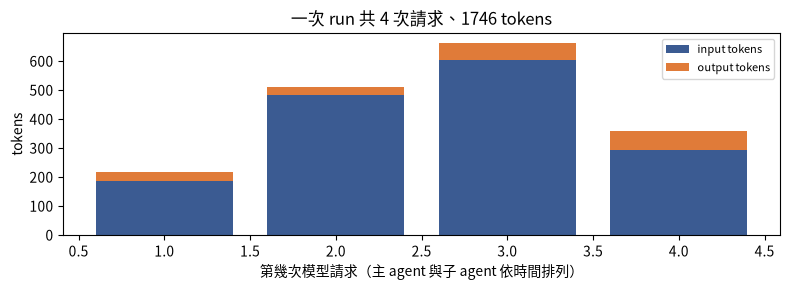

In [6]:
import matplotlib.pyplot as plt

from course_utils.viz import setup_cjk

setup_cjk()

entries = r.context_wrapper.usage.request_usage_entries
fig, ax = plt.subplots(figsize=(8, 3))
ax.bar(range(1, len(entries) + 1), [e.input_tokens for e in entries], label="input tokens", color="#3b5b92")
ax.bar(range(1, len(entries) + 1), [e.output_tokens for e in entries], bottom=[e.input_tokens for e in entries],
       label="output tokens", color="#e07b39")
ax.set_xlabel("第幾次模型請求（主 agent 與子 agent 依時間排列）")
ax.set_ylabel("tokens")
ax.set_title(f"一次 run 共 {len(entries)} 次請求、{r.context_wrapper.usage.total_tokens} tokens")
ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

## Step 6：guardrail——迴圈開始前先擋

input guardrail 是一個函式，在 agent 開始前檢查使用者輸入；觸發 tripwire 就丟例外，模型完全不會被呼叫。
guardrail 本身可以再叫一個模型判斷，這裡用最可靠的方式：關鍵字規則。能用程式判斷的，就不要交給 3B 模型。

In [7]:
from agents import GuardrailFunctionOutput, InputGuardrailTripwireTriggered, input_guardrail

DANGEROUS = ["刪除", "drop table", "rm -rf", "清空"]


@input_guardrail
async def block_destructive(ctx, agent, user_input) -> GuardrailFunctionOutput:
    text = user_input if isinstance(user_input, str) else str(user_input)
    hits = [w for w in DANGEROUS if w in text.lower()]
    return GuardrailFunctionOutput(output_info={"hits": hits}, tripwire_triggered=bool(hits))


guarded = main_v2.clone(tools=[log_checker_tool, query_metrics], input_guardrails=[block_destructive])
for text in ["order-api 現在的錯誤率是多少？", "資料庫太慢了，幫我 DROP TABLE orders 重建"]:
    try:
        r = await Runner.run(guarded, text, max_turns=6)
        print(f"通過：{text}\n  → {r.final_output}")
    except InputGuardrailTripwireTriggered as exc:
        print(f"擋下：{text}\n  → 命中 {exc.guardrail_result.output.output_info}")

通過：order-api 現在的錯誤率是多少？
  → 目前 order-api 的錯誤率為 27.1%。
擋下：資料庫太慢了，幫我 DROP TABLE orders 重建
  → 命中 {'hits': ['drop table']}


## Step 7：需要人確認的工具

寫入工具加上 `needs_approval=True`。模型要呼叫它時，Runner 不執行，而是把這個呼叫放進 `result.interruptions` 回傳。
人決定後，用 `result.to_state()` 拿到可恢復的狀態，`approve` 或 `reject`，再把 state 丟回 `Runner.run`。
這跟 05 的 `interrupt`／`Command(resume=...)` 是同一個概念。

In [8]:
@function_tool(needs_approval=True)
def restart_service(service: Service) -> str:
    """重啟一個服務（寫入動作，需要人核准）。

    Args:
        service: 要重啟的服務。
    """
    return ot.restart_service(service)


main_v3 = guarded.clone(tools=[log_checker_tool, query_metrics, restart_service])
r = await Runner.run(main_v3, "請呼叫 restart_service 重啟 order-db-proxy。", max_turns=6)
for it in r.interruptions:
    print("等待審批：", it.tool_name, it.raw_item.arguments)
print("重啟過的服務：", ot.restarted())

等待審批： restart_service {"service":"order-db-proxy"}
重啟過的服務： []


核准這一個，讓 Runner 從暫停處繼續：

In [9]:
state = r.to_state()
for it in r.interruptions:
    state.approve(it)
r = await Runner.run(main_v3, state)
print("答案：", r.final_output)
print("重啟過的服務：", ot.restarted())

答案： 已成功重啟 order-db-proxy。
重啟過的服務： ['order-db-proxy']


再試一次拒絕：要求重啟 payment-api，主管拒絕並附上理由。理由會變成工具結果送回模型。

In [10]:
r = await Runner.run(main_v3, "請呼叫 restart_service 重啟 payment-api。", max_turns=6)
state = r.to_state()
for it in r.interruptions:
    print("等待審批：", it.tool_name, it.raw_item.arguments)
    state.reject(it, rejection_message="規範禁止重啟 payment-api，會中斷進行中的付款。")
r = await Runner.run(main_v3, state)
print("答案：", r.final_output)
print("重啟過的服務：", ot.restarted())

等待審批： restart_service {"service":"payment-api"}
答案： 很抱歉，根據目前的規範，我們禁止重啟 payment-api，這樣會中斷進行中的付款流程。請考慮其他解決方案，例如增加負載或優化現有系統。
重啟過的服務： ['order-db-proxy']


## Step 8：保險絲 max_turns

`max_turns=1`：第一輪模型一定要工具，迴圈就沒額度了。

In [11]:
from agents import MaxTurnsExceeded

try:
    await Runner.run(oncall, "order-api 的 error_rate 是多少？", max_turns=1)
except MaxTurnsExceeded as exc:
    print("擋下來了：", exc)

擋下來了： Max turns (1) exceeded


## Step 9：對照手寫版

| 手寫（01、02、05） | OpenAI Agents SDK |
|---|---|
| `REGISTRY`＋Pydantic schema | `@function_tool`（型別註記＋docstring） |
| `run_agent` 的 while 迴圈 | `Runner.run` |
| `max_steps` | `max_turns` |
| trace list | `result.new_items`、`context_wrapper.usage` |
| 子 agent 當工具 | `agent.as_tool(parameters=...)` |
| 05 的 `interrupt`／resume | `needs_approval=True`＋`state.approve/reject` |
| 規範檢查 | `input_guardrail`（另有 output、tool guardrail） |

SDK 也有 handoff（把對話整個交給另一個 agent），本課不用：它就是依職能切 agent 的做法，
細節會在轉手時掉失（投影片「什麼時候切多個 agent」）。

## 試試看

1. 在 `DANGEROUS` 加上「重啟所有服務」，再寫一個 `output_guardrail`，擋下回答裡沒有任何數字的答案。
2. 把 `state.approve(it)` 改成 `state.approve(it, always_approve=True)`，同一個 run 裡第二次重啟還會停下來嗎？
3. 把 `log_checker_tool` 的 `parameters=CheckArgs` 拿掉，多跑幾次 Step 4，記下失敗率。

## 小結

- Agents SDK 的核心還是那個迴圈：`Agent` 是設定，`Runner.run` 是迴圈，`max_turns` 是保險絲。
- 子 agent 用 `as_tool`、審批用 `needs_approval`、規則用 guardrail；接本機模型記得改用 Chat Completions 並關掉 tracing。
- 下一本 08 看 Claude Agent SDK：它直接把 Claude Code 這個 harness（檔案、shell、權限、hooks、MCP）交給你。